# Домашка 3. Что видно на графиках

В каждой задаче вы строите график по данным миссии и отвечаете на вопросы
о том, что на нём видно.

Все задачи обязательные.

**Как сдать.** Ответы впишите в форму — у каждого вопроса своя метка: (1а),
(1б) и так далее. В ту же форму прикрепите эту тетрадку с построенными
графиками.

Форма для ответов: https://forms.gle/AnPSDeDQtxFjhB1K7

**Самопроверка.** Перед задачами запустите две ячейки с кодом: импорты и
«Самопроверку». Если ответ — число, в конце кода задачи есть строка
`check("1а", None)`: впишите ответ вместо `None` и запустите ячейку. Ответы-буквы
проверяются только в форме.

Вопросы по условию сюда: https://docs.google.com/forms/d/e/1FAIpQLScsri8E4OGqRMj2hbJkAB5eFR8HhsEQZqZ9AOFXx_AjtwGJ-A/viewform


## Памятка: какой график для какого вопроса

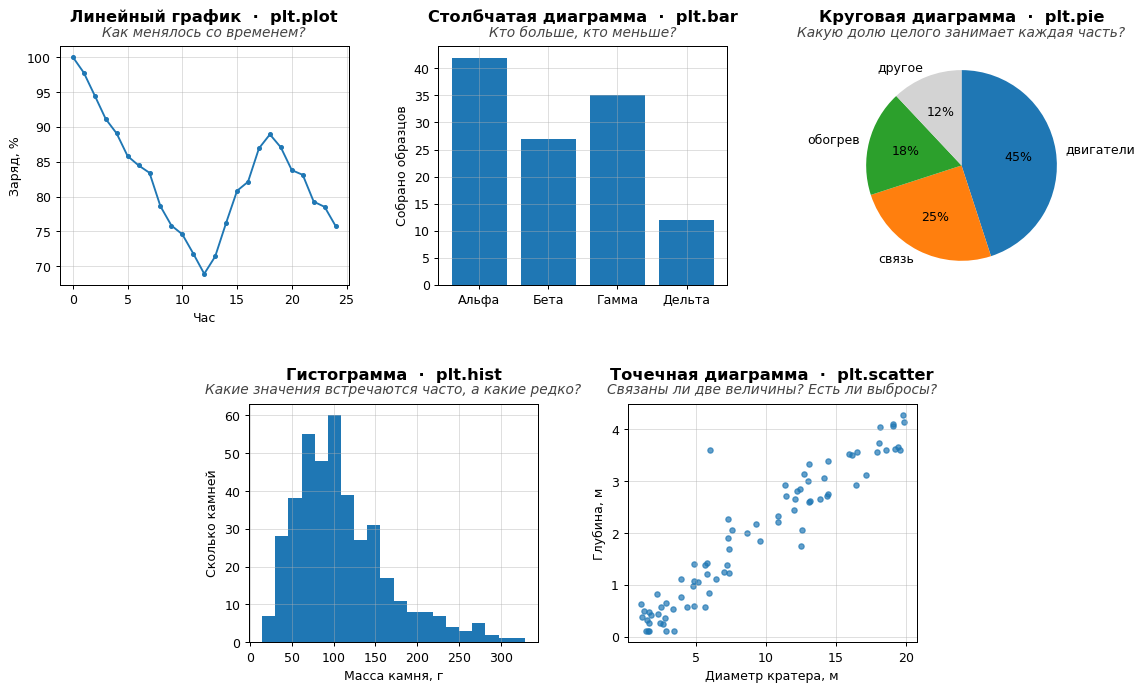


## Мини-справка по matplotlib

| Что нужно | Как |
|---|---|
| линия | `plt.plot(x, y)`, с точками — `plt.plot(x, y, marker="o")` |
| точки | `plt.scatter(x, y, s=8, alpha=0.4)` |
| гистограмма | `plt.hist(values, bins=20)` |
| горизонтальная линия | `plt.axhline(15, color="red", linestyle="--")` |
| размер картинки | `plt.figure(figsize=(10, 4))` |
| показать | `plt.show()` |

Если на одном графике несколько вызовов `plot`, `scatter` или `hist`, они
раскрашиваются по очереди: первый — синим, второй — оранжевым, третий —
зелёным. Подписать линии можно так: `plt.plot(x, y, label="...")`, потом
`plt.legend()`.

`s` в `scatter` — размер точки, `alpha` — прозрачность от 0 до 1. Когда точек
много или гистограммы перекрываются, помогает `alpha=0.5`.

Несколько графиков рядом — через `subplots`. Тогда вместо `plt.` пишут `ax[0].`,
`ax[1].` и так далее:

```python
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(values, bins=10)
ax[1].scatter(x, y, s=8)
ax[1].axhline(15, color="red")
plt.show()
```

У `ax` подписи пишутся с приставкой `set_`: `ax[0].set_title("...")`,
`ax[0].set_xlabel("...")`. `sharex=True, sharey=True` в `subplots` делает
у всех графиков одинаковые шкалы.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Файлы данных должны лежать рядом с ноутбуком.
# В Colab перетащите их в панель «Файлы» слева.

In [ ]:
# @title Самопроверка: просто запустите эту ячейку

_HASHES = {
    "1а": "dc8c4d716b28dfb4",
    "3а": "0e77bcf7bff543b6",
    "3в": "22ff97abbab89eef",
    "6а": "45d1dceb145dd17b",
}
_UNORDERED = {'К5в'}
import hashlib

def _norm(field, answer):
    if isinstance(answer, float) and answer.is_integer():
        answer = int(answer)
    s = str(answer).strip().upper()
    for lat, cyr in zip("ABCEHKMOPTXY", "АВСЕНКМОРТХУ"):
        s = s.replace(lat, cyr)
    for ch in " ,;%()[]":
        s = s.replace(ch, "")
    if s.endswith(".0"):
        s = s[:-2]
    if field in _UNORDERED:
        s = "".join(sorted(s))
    return s

def check(field, answer):
    if answer is None or str(answer).strip() == "":
        print(f"({field}) не заполнено")
        return
    if field not in _HASHES:
        print(f"({field}) — этот ответ проверяется только в форме")
        return
    key = hashlib.sha256(f"{field}:{_norm(field, answer)}".encode()).hexdigest()[:16]
    print(f"({field}) верно" if key == _HASHES[field] else f"({field}) неверно")


## 1. Сколько столбиков — столько выводов

Файл `speeds.csv`: `speed` — скорость касания поверхности в м/с у 512 прошлых
посадок.

Одни и те же числа на гистограмме выглядят по-разному — смотря сколько
столбиков (`bins`). Постройте три гистограммы рядом: с 4, 15 и 60 столбиками.

**(1а)** Сколько основных групп посадок по скорости — целое число. Считайте
только широкие горбы: отдельные узкие столбики и несколько самых быстрых
посадок справа, далеко от остальных, группами не считаются.

**(1б)** На гистограмме с 60 столбиками один столбик намного выше обоих своих
соседей. Какой скорости он соответствует? Выберите букву с ближайшим значением:

- **А** — 8 м/с
- **Б** — 12 м/с
- **В** — 22 м/с
- **Г** — 37 м/с

**(1в)** На каких гистограммах этот столбик заметен — одна буква:

- **А** — на всех трёх
- **Б** — при 15 и при 60 столбиках
- **В** — только при 60 столбиках
- **Г** — ни на одной


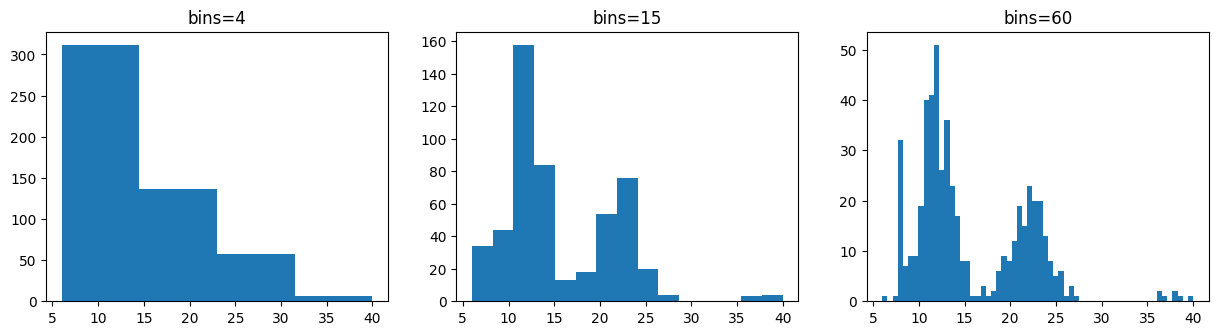

(1а) верно


In [ ]:
spd = pd.read_csv("speeds.csv")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
for a, nbins in zip(ax, [4, 15, 60]):
    a.hist(spd.speed, bins = nbins )       # гистограмма spd.speed с nbins столбиками
    a.set_title(f"bins={nbins}")
plt.show()



check("1а", 2)


In [ ]:
spd.head()

,speed
0,11.59
1,7.98
2,10.34
3,11.57
4,10.10


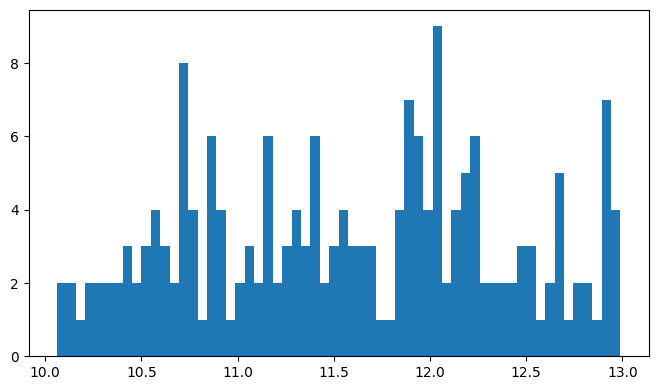

In [ ]:

speed_interval = spd.speed[(spd.speed >= 10) & (spd.speed <= 13)]

plt.figure(figsize=(8, 4.5))
plt.hist(speed_interval, bins=60)

plt.show()

## 2. Две камеры

У ровера две камеры — левая и правая. Алгоритм по снимку оценивает расстояние
до камня. Файл `cameras.csv`: `camera` — какая камера снимала (`левая` или
`правая`), `light` — освещённость снимка от 0 до 100, `error` — ошибка
алгоритма в сантиметрах.

Ошибка считается как «оценка алгоритма − настоящее расстояние», поэтому у неё
есть знак. Например, до камня 100 см: если алгоритм насчитал 105 см, ошибка
равна +5 (завысил), а если 97 см — то −3 (занизил).

Код ниже считает среднюю ошибку отдельно по тёмным снимкам (освещённость
меньше 50) и по светлым — и там и там она около нуля. Похоже, что от освещённости ошибка не зависит.

Постройте два точечных графика рядом: по горизонтали освещённость, по вертикали
ошибка. Слева — все снимки одним цветом, справа — снимки левой и правой камер
разными цветами.

**(2а)** Как ошибка зависит от освещённости — одна буква:

- **А** — у обеих камер растёт
- **Б** — у левой камеры падает, у правой растёт
- **В** — у левой камеры растёт, у правой падает
- **Г** — ни у одной камеры не зависит

**(2б)** Инженеры хотят вычитать из оценки поправку, которая зависит от
освещённости. Какая поправка нужна — одна буква:

- **А** — у каждой камеры своя
- **Б** — одна на обе камеры
- **В** — никакая: средняя ошибка и на тёмных, и на светлых снимках около нуля

**(2в)** При какой освещённости ошибки двух камер в среднем одинаковые — одна
буква:

- **А** — около 10
- **Б** — около 35
- **В** — около 65
- **Г** — ни при какой


средняя ошибка на тёмных снимках:  0.01 см
средняя ошибка на светлых снимках: 0.01 см


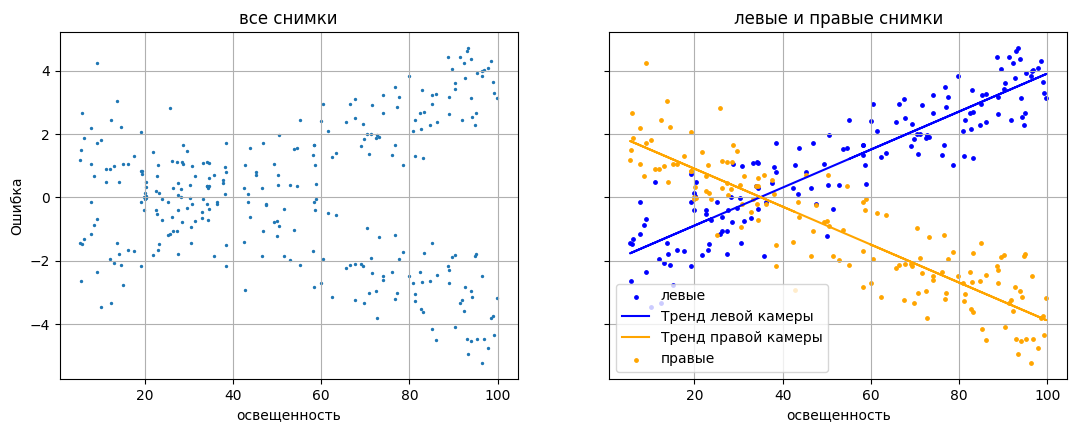

In [ ]:
cam = pd.read_csv("cameras.csv")
left = cam[cam.camera == "левая"]
right = cam[cam.camera == "правая"]


print("средняя ошибка на тёмных снимках: ", round(cam.error[cam.light < 50].mean(), 2), "см")
print("средняя ошибка на светлых снимках:", round(cam.error[cam.light >= 50].mean(), 2), "см")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True)
for a in ax:
  a.set_xlabel("освещенность")
  a.grid(True)
ax[0].set_title("все снимки")
ax[1].set_title("левые и правые снимки")
ax[0].scatter( cam["light"], cam['error'], s= 2)     # слева: все снимки
ax[0].set_ylabel("Ошибка")
ax[1].scatter(left["light"], left['error'],  s= 6, color = 'blue', label = 'левые') # справа: снимки левой камеры (будут синими)
z_left = np.polyfit(left["light"], left['error'], 1)
p_left = np.poly1d(z_left)
ax[1].plot(left["light"], p_left(left["light"]), color='blue', label='Тренд левой камеры')

z_right = np.polyfit(right["light"], right['error'], 1)
p_right = np.poly1d(z_right)
ax[1].plot(right["light"], p_right(right["light"]), color='orange', label='Тренд правой камеры')
ax[1].legend()

ax[1].scatter(right["light"], right['error'],  s= 6, color = 'orange', label = 'правые')     # справа: снимки правой камеры (будут оранжевыми)
plt.legend()




plt.show()

In [ ]:
cam['error'].mean()

np.float64(0.009800000000000027)

## 3. Обучение и проверка

**Модель** — это алгоритм, который не написан заранее, а настраивается сам:
ему показывают примеры с готовыми ответами, и он подбирает под них правила.
Эту настройку называют обучением.

Данные для неё делят на две части. На **обучении** модель настраивается — эти
примеры она видит. На **проверке** её испытывают на примерах, которых она не
видела: так понятно, как она будет работать на новых данных. Качество и там
и там — число от 0 до 1, чем больше, тем лучше.

Модель можно сделать проще или сложнее: у сложной больше настроек, и она может
подстроиться под более хитрые зависимости.

Файл `curve.csv`: `complexity` — насколько сложной разрешили быть модели
(от 1 до 15), `train` — качество на обучении, `validation` — на проверке.

Постройте на одном графике две линии: по горизонтали сложность, по вертикали
качество на обучении и качество на проверке.

**(3а)** Какую сложность выбрать, чтобы модель лучше всего работала на новых
данных — целое число.

**(3б)** Что происходит правее этой сложности — одна буква:

- **А** — модели не хватает сложности: качество низкое и на обучении, и на проверке
- **Б** — обе линии растут, только медленнее
- **В** — на обучении качество падает, а на проверке растёт
- **Г** — на обучении качество растёт, а на проверке падает


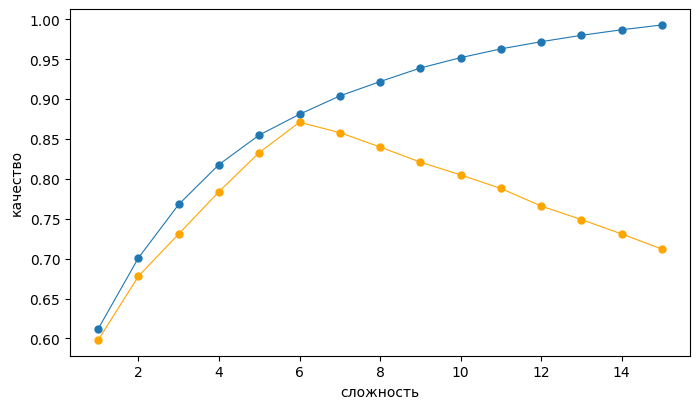

(3а) не заполнено


In [ ]:
crv = pd.read_csv("curve.csv")

plt.figure(figsize=(8, 4.5))
plt.plot( crv['complexity'], crv['train'], marker="o", markersize=5, linewidth=0.8)    # качество на обучении (линия будет синей)
plt.plot( crv['complexity'], crv['validation'], marker="o", color = 'orange',markersize=5, linewidth=0.8)  # качество на проверке (линия будет оранжевой)
plt.xlabel("сложность")
plt.ylabel("качество")
plt.show()

check("3а", None)

In [ ]:
crv.head()

,complexity,train,validation
0,1,0.612,0.598
1,2,0.701,0.678
2,3,0.768,0.731
3,4,0.818,0.784
4,5,0.855,0.833


То, что происходит правее лучшей сложности, называют **переобучением**:
модель подстраивается под особенности обучающих примеров, в том числе
случайные, и всё хуже отвечает на новые.

Качество зависит не только от сложности, но и от того, сколько модель учили.
Учится она постепенно: раз за разом просматривает все обучающие примеры и
понемногу подправляет свои настройки. Один такой проход называют **эпохой**.

Файл `epochs.csv` — как менялось качество на проверке по ходу обучения у
моделей трёх сложностей: `complexity` — сложность (2, 6 или 12), `epoch` —
номер эпохи (качество записывали каждые 5 эпох, до 60-й), `validation` —
качество на проверке.

Постройте на одном графике три линии с точками, по одной на каждую сложность:
по горизонтали эпоха, по вертикали качество.

**(3в)** Обучение останавливают на той эпохе, где качество на проверке самое
высокое. На какой эпохе остановить модель каждой сложности — три числа через
запятую: для сложности 2, для 6 и для 12 (например, `20,20,5`).


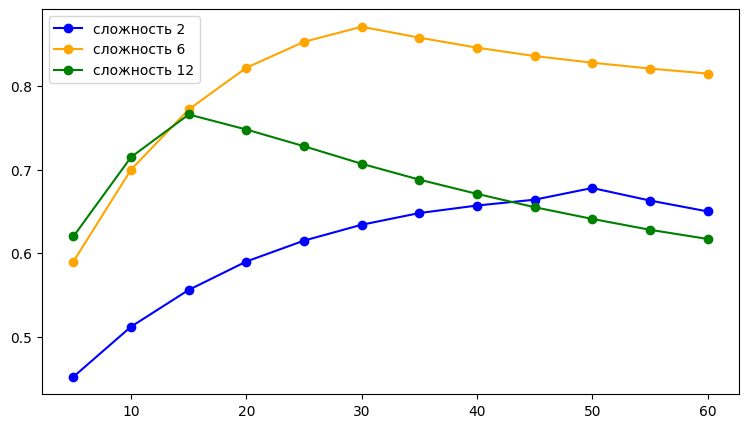

(3в) верно


In [ ]:
ep = pd.read_csv("epochs.csv")

plt.figure(figsize=(9, 5))
colors = ['blue', 'orange', 'green']
for i, c in enumerate([2, 6, 12]):
    part = ep[ep.complexity == c]
    plt.plot(part['epoch'], part['validation'], marker="o", label=f"сложность {c}", color=colors[i])
plt.legend()

plt.show()

check("3в","50,30,15" )   # три числа строкой, например "20,20,5"

In [ ]:
ep.head()

,complexity,epoch,validation
0,2,5,0.452
1,2,10,0.512
2,2,15,0.556
3,2,20,0.590
4,2,25,0.615


## 4. Ошибка маленькая — но относительно чего?

Алгоритм по снимку измеряет размер камней на месте посадки. Файл `rocks.csv`:
`true_cm` — настоящий размер камня (его измерили вручную), `measured_cm` —
сколько намерил алгоритм. Всего 400 камней, от 2 до 116 см.

Ошибку можно считать двумя способами:

- **абсолютная ошибка** — на сколько сантиметров алгоритм промахнулся:
  `(rocks.measured_cm - rocks.true_cm).abs()`;
- **относительная ошибка** — какую часть размера камня составляет промах,
  в процентах: абсолютная ошибка, делённая на настоящий размер и умноженная
  на 100. Промах на 2 см у камня размером 10 см — это относительная ошибка 20 %.

Постройте два точечных графика рядом. У обоих по горизонтали настоящий размер
камня, по вертикали на левом — абсолютная ошибка, на правом — относительная.
На правом проведите горизонтальную линию на 15 %.

**(4а)** Какие камни алгоритм измеряет хуже — одна буква:

- **А** — абсолютная ошибка больше у крупных, относительная — у мелких
- **Б** — крупные: у них больше и абсолютная, и относительная ошибка
- **В** — абсолютная ошибка больше у мелких, относительная — у крупных
- **Г** — ошибка от размера камня не зависит

**(4б)** Для ровера относительная ошибка должна быть не больше 15 %. У каких
камней она больше — одна буква:

- **А** — только у камней мельче 5 см
- **Б** — только у камней мельче 15 см
- **В** — только у камней крупнее 50 см
- **Г** — у камней любого размера


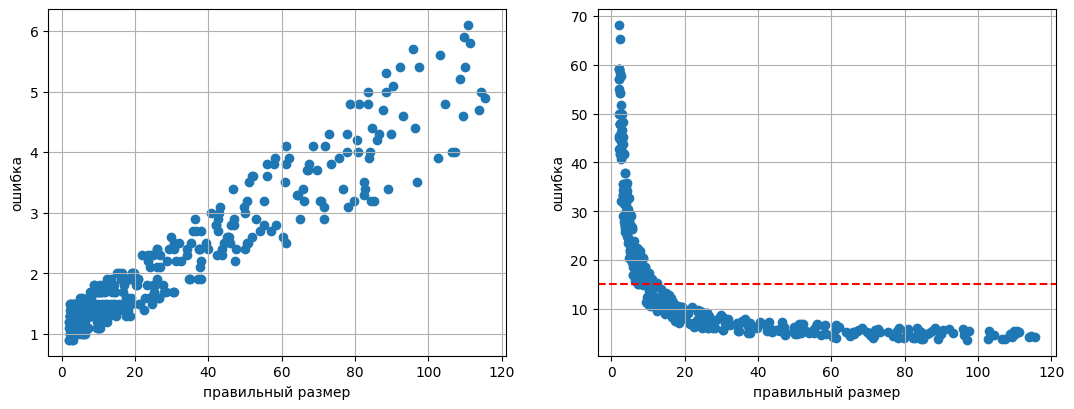

In [ ]:
rocks = pd.read_csv("rocks.csv")

err_cm = (rocks.measured_cm - rocks.true_cm).abs()
err_pct = err_cm / rocks.true_cm *100

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a in ax:
  a.set_xlabel("правильный размер")
  a.set_ylabel("ошибка")
  a.grid(True)
ax[0].scatter(rocks['true_cm'], err_cm)    # слева: размер и абсолютная ошибка
ax[1].scatter(rocks['true_cm'], err_pct) # справа: размер и относительная ошибка, линия на 15
ax[1].axhline(15,color = 'red', linestyle = '--')


plt.show()

In [ ]:
_rocks.head()

,true_cm,measured_cm
0,2.6,3.7
1,3.8,4.8
2,28.4,30.1
3,16.8,14.9
4,2.4,3.6


## 5. Ложные тревоги и пропуски

Перед посадкой алгоритм оценивает каждый участок числом от 0 до 100: чем
больше, тем опаснее. Если оценка не меньше **порога**, алгоритм поднимает
тревогу, и на этот участок не садятся.

Файл `alarms.csv` — 1000 участков, которые потом осмотрел ровер: `score` —
оценка алгоритма, `dangerous` — 1, если участок на самом деле опасный, 0 —
если безопасный.

Ошибиться алгоритм может двумя способами:

- **ложная тревога** — участок безопасный, а тревога поднята;
- **пропуск** — участок опасный, а тревоги нет.

Чем выше порог, тем меньше ложных тревог, но тем больше пропусков. Насколько
удачен порог, описывают двумя долями — код ниже считает их для всех порогов
от 0 до 100:

- **доля пойманных** — какая часть опасных участков получила тревогу;
- **доля верных тревог** — какая часть тревог пришлась на опасные участки.

Постройте два графика рядом:

1. гистограммы оценок безопасных и опасных участков на одном графике —
   с одинаковыми столбиками `bins=range(0, 101, 5)` и `alpha=0.5`, чтобы было
   видно, где они перекрываются;
2. обе доли в зависимости от порога — две линии.

**(5а)** Как соотносятся оценки безопасных и опасных участков — одна буква:

- **А** — у безопасных оценки в основном выше
- **Б** — у опасных оценки выше, и два вида оценок не пересекаются
- **В** — у опасных оценки в основном выше, но часть оценок перекрывается
- **Г** — у безопасных и опасных оценки почти одинаковые

**(5б)** Требования: поймать не меньше 90 % опасных участков, и чтобы не
меньше 60 % тревог были верными. Какой порог подходит — одна буква:

- **А** — 30
- **Б** — 50
- **В** — 60
- **Г** — 70

**(5в)** Требования ужесточили: поймать не меньше 95 % опасных, и верных тревог
не меньше 90 %. Какой порог подходит — одна буква:

- **А** — 45
- **Б** — 53
- **В** — 58
- **Г** — никакой: оба требования сразу не выполняются ни при одном пороге

В машинном обучении доля пойманных называется **полнотой** (recall), а доля
верных тревог — **точностью** (precision).


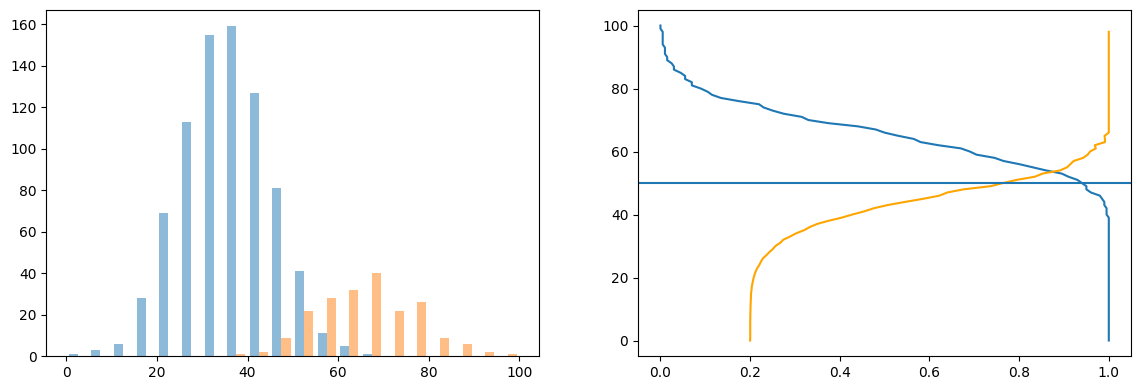

In [ ]:
alr = pd.read_csv("alarms.csv")
safe = alr.score[alr.dangerous == 0]
danger = alr.score[alr.dangerous == 1]

thresholds = np.arange(0, 101)
caught, correct = [], []
for t in thresholds:
    alarm = alr.score >= t
    hits = (alarm & (alr.dangerous == 1)).sum()
    caught.append(hits / len(danger))
    correct.append(hits / alarm.sum() if alarm.sum() > 0 else np.nan)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist([safe, danger], bins=range(0, 101, 5), alpha=0.5)     # слева: гистограммы оценок safe (синяя) и danger (оранжевая)
ax[1].plot(caught, thresholds)
ax[1].plot(correct, thresholds, color = 'orange')
  # справа: caught (синяя линия) и correct (оранжевая) по thresholds
plt.axhline(50)
plt.show()

In [ ]:
alr.head()

,score,dangerous
0,68,1
1,30,0
2,50,0
3,75,1
4,30,0


## 6. Свой график


Файл `mystery.csv` — сутки показаний трёх приборов:
`minute` — минуты от полуночи (0 — это 00:00, 60 — это 01:00 и так далее),
`temperature` — температура за бортом,
`power` — мощность реактора,
`signal` — уровень сигнала.

Здесь нет инструкции, что строить. С одним из приборов за эти сутки случился
сбой. Стройте любые графики, пока не увидите, с каким именно и когда.
График, по которому вы это поняли, оставьте в тетрадке.

**(6а)** В каком часу начался сбой — целое число от 0 до 23.

**(6б)** Что случилось — одна буква:

- **А** — температура за бортом резко подскочила и больше не опускалась
- **Б** — мощность реактора перестала меняться: почти час подряд идёт одно и то же число
- **В** — уровень сигнала стал скакать намного сильнее обычного
- **Г** — мощность реактора плавно упала до нуля


In [ ]:
mys = pd.read_csv("mystery.csv")
print(mys.shape)
mys.head()

(1440, 4)


,minute,temperature,power,signal
0,0,-61.25,100.05,61.77
1,1,-61.43,99.45,62.64
2,2,-62.12,98.61,61.41
3,3,-62.06,99.08,61.81
4,4,-61.08,98.43,59.79


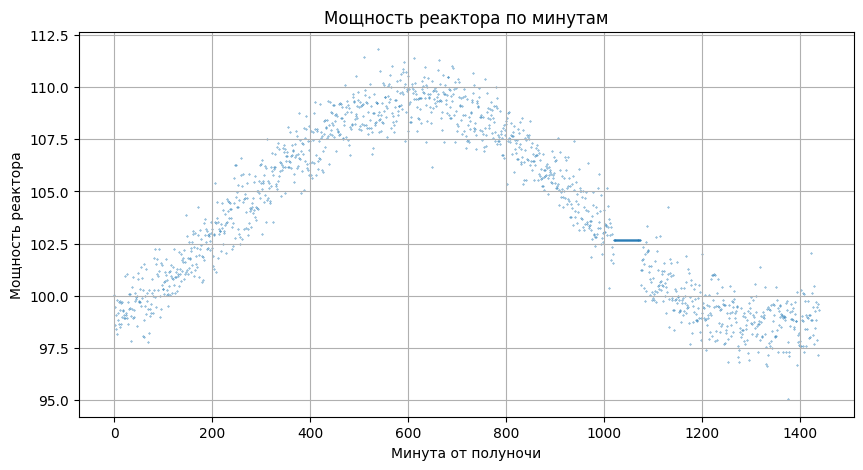

In [ ]:
plt.figure( figsize = (10,5))
plt.scatter(mys['minute'], mys['power'], s = 0.1)
plt.xlabel("Минута от полуночи")
plt.ylabel("Мощность реактора")
plt.title("Мощность реактора по минутам")
plt.grid(True)
plt.show()

In [ ]:
check("6а", 17)

In [ ]:
plt.figure(figsize=(7, 4))
plt.hist(df["waiting"], bins=15)  # или bins=range(40, 101, 5)

# Вертикальная линия порога/среднего
plt.axvline(df["waiting"].mean(), color="red", linestyle="--", label=f"Среднее: {df['waiting'].mean():.1f}")
plt.xlabel("Время ожидания, мин")
plt.ylabel("Число наблюдений")
plt.title("Распределение времени ожидания")
plt.legend()
plt.show()